In [1]:
import pandas as pd 
import numpy as np   
import seaborn as sns  
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.spatial.distance import cdist, pdist 
from scipy.cluster.hierarchy import dendrogram, ward, average, complete
from sklearn.metrics import silhouette_score

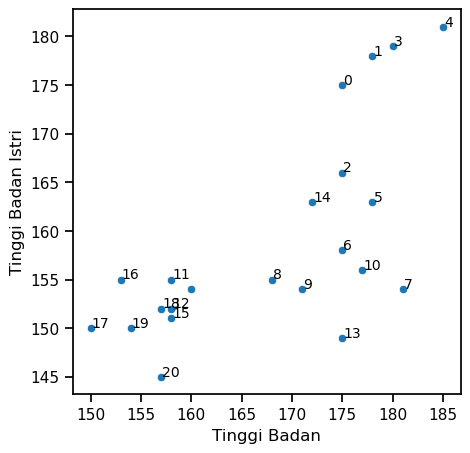

In [2]:
# import data and visualize
df = pd.read_csv('Dataset/ilustrasi_k_means.csv',sep=';')

plt.figure(figsize = (5,5))
sns.set_context('notebook', font_scale=1)
sns.scatterplot(
    x = 'tinggibadan', 
    y = 'tinggibadanistri', 
    data = df)
plt.xlabel('Tinggi Badan')
plt.ylabel('Tinggi Badan Istri')
for i, txt in enumerate(range(0, df.shape[0]-1)):
    plt.annotate(txt, (df['tinggibadan'][i]+0.1, df['tinggibadanistri'][i]+0.1), fontsize=10)

Text(0, 0.5, 'Cluster Distance')

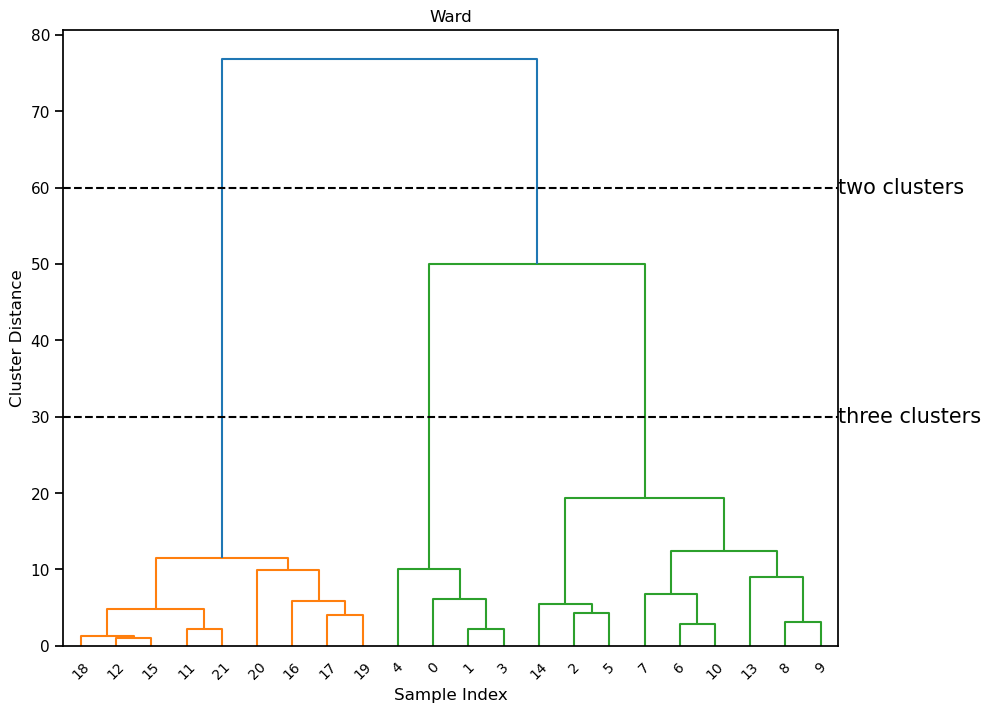

In [3]:
# visualize dendogram
linkage_array = ward(df)

plt.figure(figsize=(10,8))

dendrogram(linkage_array,25)
ax= plt.gca()
bounds = ax.get_xbound()
ax.plot(bounds, [60,60],'--', c ='k')
ax.plot(bounds, [30,30],'--', c ='k')
ax.text(bounds[1],60,'two clusters',va='center', fontdict={'size':15}) # annotations 1
ax.text(bounds[1],30,'three clusters',va='center', fontdict={'size':15}) # annotations 2

plt.title('Ward')
plt.xlabel('Sample Index')
plt.ylabel('Cluster Distance')

Text(0, 0.5, 'Cluster Distance')

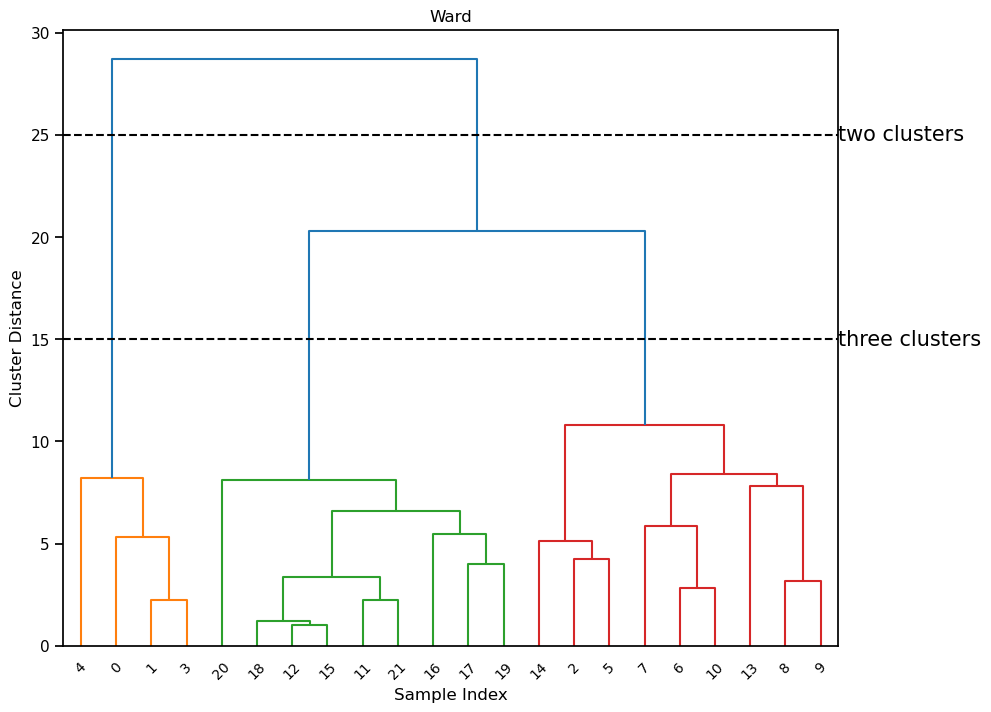

In [4]:
# visualize dendogram 'average
linkage_array = average(df)

plt.figure(figsize=(10,8))

dendrogram(linkage_array,25)
ax= plt.gca()
bounds = ax.get_xbound()
ax.plot(bounds, [25,25],'--', c ='k')
ax.plot(bounds, [15,15],'--', c ='k')
ax.text(bounds[1],25,'two clusters',va='center', fontdict={'size':15}) # annotations 1
ax.text(bounds[1],15,'three clusters',va='center', fontdict={'size':15}) # annotations 2

plt.title('Ward')
plt.xlabel('Sample Index')
plt.ylabel('Cluster Distance')

Text(0, 0.5, 'Cluster Distance')

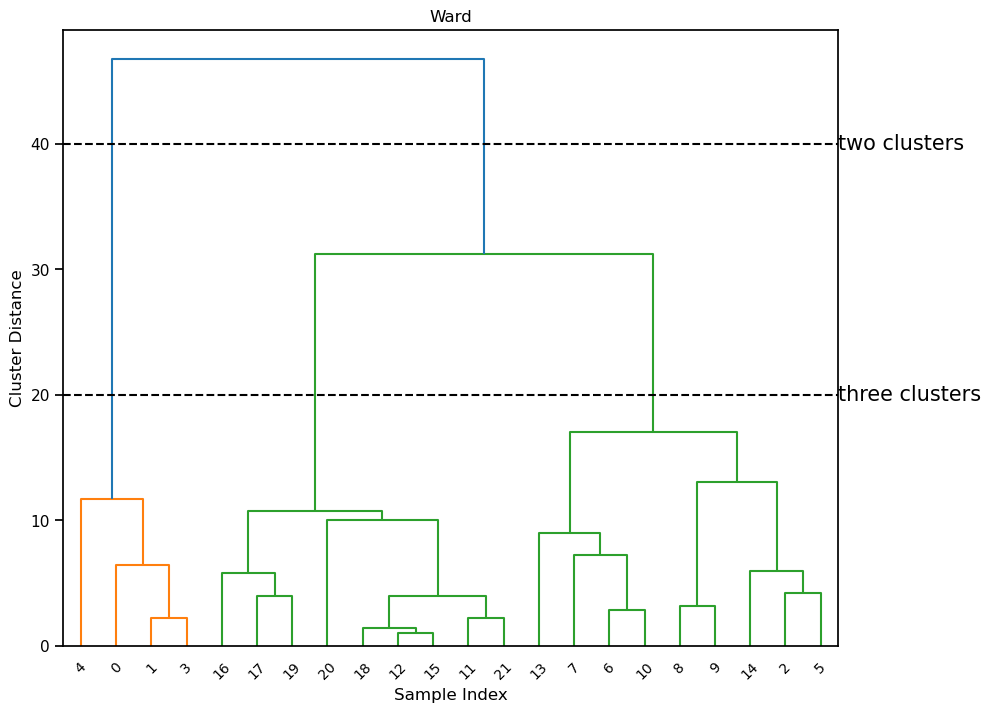

In [5]:
# visualize dendogram 'complete'
linkage_array = complete(df)

plt.figure(figsize=(10,8))

dendrogram(linkage_array,25)
ax= plt.gca()
bounds = ax.get_xbound()
ax.plot(bounds, [40,40],'--', c ='k')
ax.plot(bounds, [20,20],'--', c ='k')
ax.text(bounds[1],40,'two clusters',va='center', fontdict={'size':15}) # annotations 1
ax.text(bounds[1],20,'three clusters',va='center', fontdict={'size':15}) # annotations 2

plt.title('Ward')
plt.xlabel('Sample Index')
plt.ylabel('Cluster Distance')

In [21]:
# result comparison
agg_ward = AgglomerativeClustering(n_clusters=3, linkage = 'ward')
df['ward'] = agg_ward.fit_predict(df)
agg_average = AgglomerativeClustering(n_clusters=3, linkage = 'average')
df['average'] = agg_average.fit_predict(df)
agg_complete = AgglomerativeClustering(n_clusters=3, linkage = 'complete')
df['complete'] = agg_complete.fit_predict(df)
df

,tinggibadan,tinggibadanistri,ward,average,complete
0,175,175,2,1,1
1,178,178,2,1,1
2,175,166,0,0,0
3,180,179,2,1,1
4,185,181,2,1,1
5,178,163,0,0,0
6,175,158,0,0,0
7,181,154,0,0,0
8,168,155,0,0,0
9,171,154,0,0,0


In [22]:
# DBSCAN
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
df_scaled

array([[ 0.66695822,  1.56643226,  1.67125804,  0.        ,  0.        ],
       [ 0.95095333,  1.85765628,  1.67125804,  0.        ,  0.        ],
       [ 0.66695822,  0.69276018, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 1.14028341,  1.95473096,  1.67125804,  0.        ,  0.        ],
       [ 1.6136086 ,  2.14888031,  1.67125804,  0.        ,  0.        ],
       [ 0.95095333,  0.40153616, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 0.66695822, -0.08383722, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 1.23494845, -0.47213592, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 0.00430296, -0.37506124, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 0.28829807, -0.47213592, -1.05227358, -1.1055416 , -1.1055416 ],
       [ 0.8562883 , -0.27798657, -1.05227358, -1.1055416 , -1.1055416 ],
       [-0.94234742, -0.37506124,  0.30949223,  1.1055416 ,  1.1055416 ],
       [-0.94234742, -0.66628527,  0.30949223,  1.1055416 ,  1.1055416 ],
       [ 0.66695822, -0.95750929, -1.0

In [23]:
dbscan = DBSCAN(eps = 0.8, min_samples=6)
clusters = dbscan.fit_predict(df_scaled)

In [24]:
clusters 

array([-1, -1,  0, -1, -1,  0,  0,  0,  0,  0,  0,  1,  1,  0,  0,  1,  1,
        1,  1,  1,  1,  1], dtype=int64)

In [25]:
silhouette_score(df_scaled,clusters)

0.8201288826817883

In [26]:
# we're gonna try t find the optimum epsilon and min_samples
# try 0.6 0.7 0.8 for epsilon
# try min_samples for 6,7

for eps in [i/10 for i in range(6,8)]:
    for min_samples in range(4,6):
        print('\neps = {}'.format(eps))
        print('min_samples = {}'.format(min_samples))
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(df_scaled)
        silh = silhouette_score(df_scaled,labels)
        print('Cluster Present = {}'.format(np.unique(labels)))
        print('Cluster Sizes = {}'.format(np.bincount(labels+1)))
        print('Silhouette Score = {}'.format(silh))


eps = 0.6
min_samples = 4
Cluster Present = [-1  0  1]
Cluster Sizes = [7 6 9]
Silhouette Score = 0.5234171355789123

eps = 0.6
min_samples = 5
Cluster Present = [-1  0  1]
Cluster Sizes = [8 5 9]
Silhouette Score = 0.44923301155598244

eps = 0.7
min_samples = 4
Cluster Present = [0 1 2]
Cluster Sizes = [0 4 9 9]
Silhouette Score = 0.8201288826817883

eps = 0.7
min_samples = 5
Cluster Present = [-1  0  1]
Cluster Sizes = [4 9 9]
Silhouette Score = 0.8201288826817883


In [27]:
# final result
final_dbscan = DBSCAN(eps=0.7, min_samples=5)
clusters = final_dbscan.fit_predict(df_scaled)

In [30]:
df['dbscan_cluster'] = clusters
print(clusters)

[-1 -1  0 -1 -1  0  0  0  0  0  0  1  1  0  0  1  1  1  1  1  1  1]


Text(0, 0.5, 'Tinggi Badan Istri')

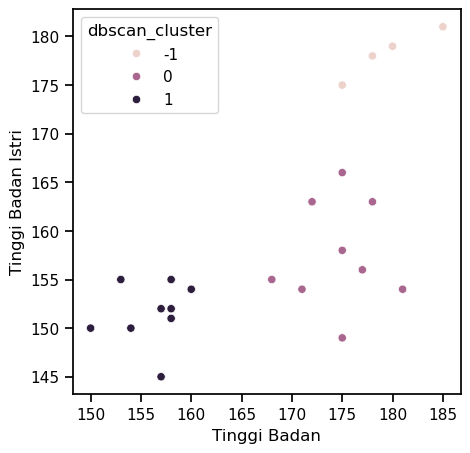

In [31]:
# visualziations : complete method clustering
plt.figure(figsize = (5,5))
sns.set_context('notebook', font_scale=1)
sns.scatterplot(
    x = 'tinggibadan', 
    y = 'tinggibadanistri', 
    data = df,
    hue ='dbscan_cluster')
plt.xlabel('Tinggi Badan')
plt.ylabel('Tinggi Badan Istri')